# Import libraries

In [ ]:
import sys
github_repo_url = "https://github.com/AnnaEls/HAADF-STEM-image-denoising.git"
!git clone {github_repo_url}
sys.path.append('/content/HAADF-STEM-image-denoising')

Cloning into 'HAADF-STEM-image-denoising'...
remote: Enumerating objects: 1535, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 1535 (delta 10), reused 2 (delta 2), pack-reused 1510 (from 1)
Receiving objects: 100% (1535/1535), 143.56 MiB | 11.24 MiB/s, done.
Resolving deltas: 100% (689/689), done.
Updating files: 100% (278/278), done.


In [ ]:
!pip install hyperspy
!pip install atomap

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import h5py
import tifffile
from Models.hybrid_model import hybrid_model
from Models.UNet import init_unet_kaiming
from Utilities.Utils import prepare_input, convert
from Training.Training import train_hybrid_model

import hyperspy.api as hs
import atomap as am
from Analysis.gaussian_detection_atomap import find_atoms, compare_sublattices_with_lattice_fp_classification, plot_atom_classification

/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


# Analysis

In [ ]:
SEPARATION = 3
MATCH_TOLERANCE=5.0,
LATTICE_TOLERANCE=5.0,
NEIGHBOR_RADIUS=35

## Processing clean image

Center of mass:   0%|          | 0/263 [00:00<?, ?it/s]

Gaussian fitting:   0%|          | 0/263 [00:00<?, ?it/s]

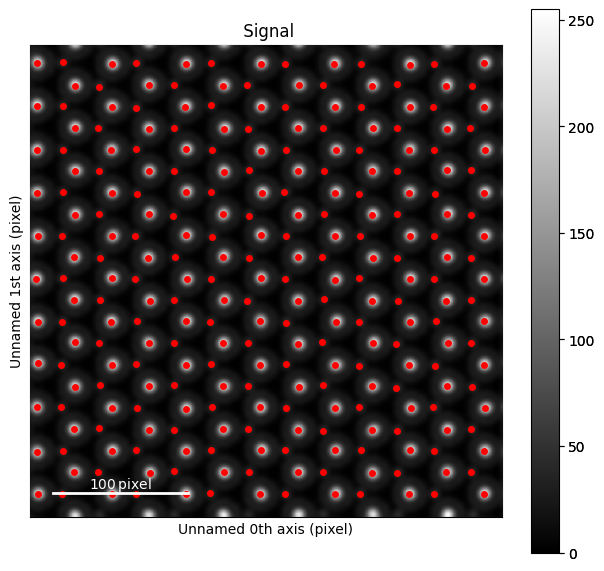

In [ ]:
path_to_clean_image = "/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/WS2-ground_truth_interp_0.1_dose_no_noise.tif"
clean_image = convert(tifffile.imread(path_to_clean_image))
s = hs.signals.Signal2D(clean_image)
clean_sublattice = find_atoms(s, separation = SEPARATION, plot = True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
import atomap as am


def find_sublattices(sublattice, image, plot=True):

    features = []

    for atom in sublattice.atom_list:
        amplitude = atom.amplitude_gaussian
        sigma_avg = (atom.sigma_x + atom.sigma_y) / 2.0
        features.append([amplitude, sigma_avg])

    X = np.array(features)

    # --------------------------------------------------
    # K-means clustering
    # --------------------------------------------------
    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    # --------------------------------------------------
    # Make sure Cluster_0 has the higher amplitude
    # --------------------------------------------------
    mean_amp_0 = X[labels == 0, 0].mean()
    mean_amp_1 = X[labels == 1, 0].mean()

    if mean_amp_1 > mean_amp_0:
        labels = 1 - labels   # swap 0 <-> 1

    # --------------------------------------------------
    # Create sublattices
    # --------------------------------------------------
    coords_cluster_0 = [
        [atom.pixel_x, atom.pixel_y]
        for i, atom in enumerate(sublattice.atom_list)
        if labels[i] == 0
    ]

    coords_cluster_1 = [
        [atom.pixel_x, atom.pixel_y]
        for i, atom in enumerate(sublattice.atom_list)
        if labels[i] == 1
    ]

    sublattice_0 = am.sublattice.Sublattice(
        atom_position_list=coords_cluster_0,
        image=image
    )

    sublattice_1 = am.sublattice.Sublattice(
        atom_position_list=coords_cluster_1,
        image=image
    )

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    if plot:

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Cluster 0 - HIGH amplitude
        axes[0].imshow(image, cmap='gray')

        x_0 = [atom.pixel_x for atom in sublattice_0.atom_list]
        y_0 = [atom.pixel_y for atom in sublattice_0.atom_list]

        axes[0].scatter(
            x_0,
            y_0,
            color='blue',
            s=30,
            label='Cluster 0'
        )

        axes[0].set_title('Cluster 0 - Higher amplitude')
        axes[0].legend()
        axes[0].axis('off')

        # Cluster 1 - LOW amplitude
        axes[1].imshow(image, cmap='gray')

        x_1 = [atom.pixel_x for atom in sublattice_1.atom_list]
        y_1 = [atom.pixel_y for atom in sublattice_1.atom_list]

        axes[1].scatter(
            x_1,
            y_1,
            color='red',
            s=30,
            label='Cluster 1'
        )

        axes[1].set_title('Cluster 1 - Lower amplitude')
        axes[1].legend()
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

    return sublattice_0, sublattice_1

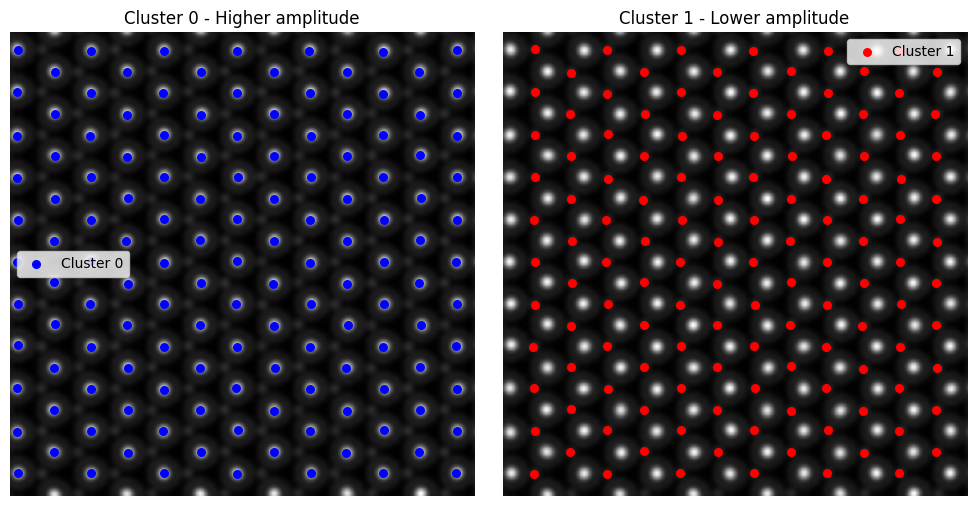

126


In [ ]:
sublattice_W_clean, sublattice_S_clean = find_sublattices(clean_sublattice, clean_image)
N_S = len(sublattice_S_clean.atom_list)
print(N_S)

## Processing denoised image: hybrid model

In [ ]:
doses = [100000.0, 50000.0, 10000.0, 5000.0]
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_hybrid/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif"
    image = tifffile.imread(image_path)
    s = hs.load(image_path)
    noisy_sublattice = find_atoms(s, separation = SEPARATION, plot = True)
    plt.show()
    atom_data = []
    for atom in noisy_sublattice.atom_list:
      atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
    df_gaussians = pd.DataFrame(atom_data)
    df_gaussians.to_csv(output_path + f'gaussians_image_ID_dose_{dose}_denoised_hybrid.csv', index=False)
    sublattice_W_noisy, sublattice_S_noisy = find_sublattices(noisy_sublattice, image)
    results = compare_sublattices_with_lattice_fp_classification(
        sublattice_S_clean,
        sublattice_S_noisy,
        image_shape=image.shape,
        match_tolerance=MATCH_TOLERANCE,
        lattice_tolerance=LATTICE_TOLERANCE,
        neighbor_radius=NEIGHBOR_RADIUS)
    plot_atom_classification(image, sublattice_S_clean, sublattice_S_noisy, results)
    rows.append({"dose": dose, "rmse": np.round(results["rmse_error"], 2), "TP": results["num_true_positives"], "FN": results["num_false_negatives"], "FP": results["num_false_positives"] })


In [ ]:
N_TP = len(sublattice_S_clean.atom_list)
df = pd.DataFrame(rows)
N_atoms = N_TP

# False negatives
df["FN"] = N_atoms - df["TP"]

# Precision
df["Precision"] = np.round(
    df["TP"] / (df["TP"] + df["FP"]),
    2
)

# Recall
df["Recall"] = np.round(
    df["TP"] / (df["TP"] + df["FN"]),
    2
)

# F1 score
df["F1"] = np.round(
    2 * df["TP"] / (2 * df["TP"] + df["FP"] + df["FN"]),
    2
)


display(df)

,dose,rmse,TP,FN,FP,Precision,Recall,F1
0,100000.0,0.84,126,0,4,0.97,1.00,0.98
1,50000.0,1.11,126,0,1,0.99,1.00,1.00
2,10000.0,1.16,126,0,47,0.73,1.00,0.84
3,5000.0,1.42,125,1,41,0.75,0.99,0.86


## Processing denoised image: Lobato model

In [ ]:
doses = [100000.0, 50000.0, 10000.0, 5000.0]
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_lobato/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif"
    image = convert(tifffile.imread(image_path))
    s = hs.load(image_path)
    noisy_sublattice = find_atoms(s, separation = SEPARATION, plot = True)
    plt.show()
    atom_data = []
    for atom in noisy_sublattice.atom_list:
      atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
    df_gaussians = pd.DataFrame(atom_data)
    df_gaussians.to_csv(output_path + f'gaussians_image_ID_dose_{dose}_denoised_lobato.csv', index=False)
    sublattice_W_noisy, sublattice_S_noisy = find_sublattices(noisy_sublattice, image)
    results = compare_sublattices_with_lattice_fp_classification(
        sublattice_S_clean,
        sublattice_S_noisy,
        image_shape=image.shape,
        match_tolerance=MATCH_TOLERANCE,
        lattice_tolerance=LATTICE_TOLERANCE,
        neighbor_radius=NEIGHBOR_RADIUS)
    plot_atom_classification(image, sublattice_S_clean, sublattice_S_noisy, results)
    rows.append({"dose": dose, "rmse": np.round(results["rmse_error"], 2), "TP": results["num_true_positives"], "FN": results["num_false_negatives"], "FP": results["num_false_positives"] })


In [ ]:
N_TP = len(sublattice_S_clean.atom_list)
df = pd.DataFrame(rows)
N_atoms = N_TP

# False negatives
df["FN"] = N_atoms - df["TP"]

# Precision
df["Precision"] = np.round(
    df["TP"] / (df["TP"] + df["FP"]),
    2
)

# Recall
df["Recall"] = np.round(
    df["TP"] / (df["TP"] + df["FN"]),
    2
)

# F1 score
df["F1"] = np.round(
    2 * df["TP"] / (2 * df["TP"] + df["FP"] + df["FN"]),
    2
)


display(df)

,dose,rmse,TP,FN,FP,Precision,Recall,F1
0,100000.0,1.39,126,0,54,0.70,1.00,0.82
1,50000.0,1.72,123,3,39,0.76,0.98,0.85
2,10000.0,2.55,68,58,30,0.69,0.54,0.61
3,5000.0,2.72,37,89,49,0.43,0.29,0.35


## Processing denoised image: Pinto model

In [ ]:
doses = [100000.0, 50000.0, 10000.0, 5000.0]
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_pinto/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif"
    image = convert(tifffile.imread(image_path))
    s = hs.load(image_path)
    noisy_sublattice = find_atoms(s, separation = 7, plot = True)
    plt.show()
    atom_data = []
    for atom in noisy_sublattice.atom_list:
      atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
    df_gaussians = pd.DataFrame(atom_data)
    df_gaussians.to_csv(output_path + f'gaussians_image_ID_dose_{dose}_denoised_pinto.csv', index=False)
    sublattice_W_noisy, sublattice_S_noisy = find_sublattices(noisy_sublattice, image)
    results = compare_sublattices_with_lattice_fp_classification(
        sublattice_S_clean,
        sublattice_S_noisy,
        image_shape=image.shape,
        match_tolerance=MATCH_TOLERANCE,
        lattice_tolerance=MATCH_TOLERANCE,
        neighbor_radius=NEIGHBOR_RADIUS)
    plot_atom_classification(image, sublattice_S_clean, sublattice_S_noisy, results)
    rows.append({"dose": dose, "rmse": np.round(results["rmse_error"], 2), "TP": results["num_true_positives"], "FN": results["num_false_negatives"], "FP": results["num_false_positives"] })


In [ ]:
N_TP = len(sublattice_S_clean.atom_list)
df = pd.DataFrame(rows)
N_atoms = N_TP

# False negatives
df["FN"] = N_atoms - df["TP"]

# Precision
df["Precision"] = np.round(
    df["TP"] / (df["TP"] + df["FP"]),
    2
)

# Recall
df["Recall"] = np.round(
    df["TP"] / (df["TP"] + df["FN"]),
    2
)

# F1 score
df["F1"] = np.round(
    2 * df["TP"] / (2 * df["TP"] + df["FP"] + df["FN"]),
    2
)


display(df)

,dose,rmse,TP,FN,FP,Precision,Recall,F1
0,100000.0,1.77,119,7,9,0.93,0.94,0.94
1,50000.0,1.81,120,6,9,0.93,0.95,0.94
2,10000.0,2.44,70,56,89,0.44,0.56,0.49
3,5000.0,2.93,77,49,102,0.43,0.61,0.50


## Processing denoised image: UNIT model

In [ ]:
doses = [100000.0, 50000.0, 10000.0, 5000.0]
rows = []
for dose in doses:
    print("Dose:" + str(dose))
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_unit/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_unit_aligned.tif"
    image = tifffile.imread(image_path)
    s = hs.load(image_path)
    noisy_sublattice = find_atoms(s, separation = SEPARATION, plot = True)
    plt.show()
    atom_data = []
    for atom in noisy_sublattice.atom_list:
      atom_data.append({
        'x': atom.pixel_x,
        'y': atom.pixel_y,
        'sx': atom.sigma_x,
        'sy': atom.sigma_y,
        'r': atom.rotation,
        'e': atom.ellipticity,
        'amplitude_gaussian': atom.amplitude_gaussian
       })
    df_gaussians = pd.DataFrame(atom_data)
    df_gaussians.to_csv(output_path + f'gaussians_image_ID_dose_{dose}_denoised_unit.csv', index=False)
    sublattice_W_noisy, sublattice_S_noisy = find_sublattices(noisy_sublattice, image)
    results = compare_sublattices_with_lattice_fp_classification(
        sublattice_S_clean,
        sublattice_S_noisy,
        image_shape=image.shape,
        match_tolerance=MATCH_TOLERANCE,
        lattice_tolerance=LATTICE_TOLERANCE,
        neighbor_radius=NEIGHBOR_RADIUS)
    plot_atom_classification(image, sublattice_S_clean, sublattice_S_noisy, results)
    rows.append({"dose": dose, "rmse": np.round(results["rmse_error"], 2), "TP": results["num_true_positives"], "FN": results["num_false_negatives"], "FP": results["num_false_positives"] })


In [ ]:
N_TP = len(sublattice_S_clean.atom_list)
df = pd.DataFrame(rows)
N_atoms = N_TP

# False negatives
df["FN"] = N_atoms - df["TP"]

# Precision
df["Precision"] = np.round(
    df["TP"] / (df["TP"] + df["FP"]),
    2
)

# Recall
df["Recall"] = np.round(
    df["TP"] / (df["TP"] + df["FN"]),
    2
)

# F1 score
df["F1"] = np.round(
    2 * df["TP"] / (2 * df["TP"] + df["FP"] + df["FN"]),
    2
)


display(df)

,dose,rmse,TP,FN,FP,Precision,Recall,F1
0,100000.0,1.28,126,0,6,0.95,1.00,0.98
1,50000.0,1.50,124,2,7,0.95,0.98,0.96
2,10000.0,2.37,108,18,16,0.87,0.86,0.86
3,5000.0,2.65,91,35,29,0.76,0.72,0.74


# Plotting

In [ ]:
models = ["Noisy", "Hybrid", "Lobato", "Pinto", "UNIT"]
images_1 = []
doses = {100000.0}
for dose in doses:
    # Noisy:
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}.tif"
    image = tifffile.imread(image_path)
    images_1.append(image)
    #Hybrid
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_hybrid/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif"
    image = tifffile.imread(image_path)
    images_1.append(image)
    #Lobato
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_lobato/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif"
    image = tifffile.imread(image_path)
    images_1.append(image)
    #Pinto
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_pinto/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif"
    image = convert(tifffile.imread(image_path))
    images_1.append(image)
    #UNIT
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_unit/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_unit_aligned.tif"
    image = tifffile.imread(image_path)
    images_1.append(image)

In [ ]:
models = ["Noisy", "Hybrid", "Lobato", "Pinto", "UNIT"]
images_2 = []
doses = {5000.0}
for dose in doses:
    # Noisy:
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}.tif"
    image = tifffile.imread(image_path)
    images_2.append(image)
    #Hybrid
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_hybrid/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_hybrid.tif"
    image = tifffile.imread(image_path)
    images_2.append(image)
    #Lobato
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_lobato/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_restored_sfr_hrstem.tif"
    image = tifffile.imread(image_path)
    images_2.append(image)
    #Pinto
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_pinto/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_denoised_pinto.tif"
    image = convert(tifffile.imread(image_path))
    images_2.append(image)
    #UNIT
    output_path = f"/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/denoised_unit/"
    image_path = output_path + f"WS2-jittered_interp_0.1_dose_{dose}_unit_aligned.tif"
    image = tifffile.imread(image_path)
    images_2.append(image)

In [ ]:
images_c = []
image_path = "/content/HAADF-STEM-image-denoising/Datasets/DATASET_WS2/WS2-ground_truth_interp_0.1_dose_no_noise.tif"
image = tifffile.imread(image_path)
images_c.append(image)

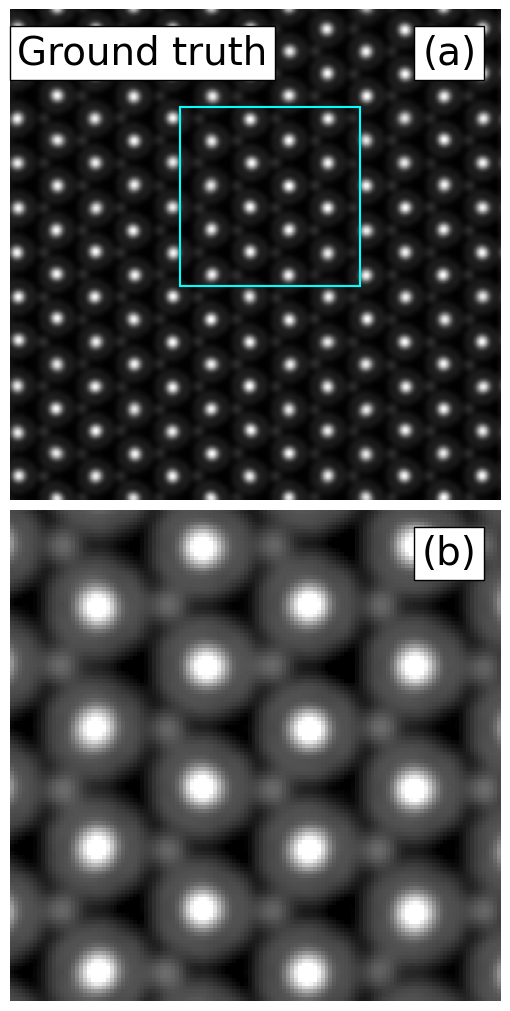

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure, exposure
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
images = images_c
models = ["Ground truth"]
letters_img = ["(a)", "(b)", "(c)", "(d)", "(e)"]
letters_patch = ["(b)", "(g)", "(h)", "(i)", "(j)"]
point1 = (14, 116)
point2 = (253, 254)

patch_size = 128  # pixels

n = len(images)
sub = 2

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images):
    # ---------- PATCH center (midpoint of line) ----------
    cy = int(0.5 * (point1[0] + point2[0]))
    cx = int(0.5 * (point1[1] + point2[1]))
    r = patch_size // 2

    y0 = max(cy - r, 0)
    x0 = max(cx - r, 0)
    y1 = min(cy + r, image.shape[0])
    x1 = min(cx + r, image.shape[1])

    patch = image[y0:y1, x0:x1]

    # Histogram normalization (robust)
    p2, p98 = np.percentile(patch, (2, 98))
    patch_norm = exposure.rescale_intensity(
        patch, in_range=(p2, p98), out_range=(0, 1)
    )
    # Brightness boost (gamma correction)
    gamma = 0.6
    patch_bright = exposure.adjust_gamma(patch_norm, gamma)
    # ---------- TOP: full image ----------
    ax_img = fig.add_subplot(gs[0, idx])

    ax_img.imshow(image, cmap='gray')




    # Patch rectangle
    rect = Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        linewidth=1.5,
        edgecolor='cyan',
        facecolor='none'
    )
    ax_img.add_patch(rect)

    ax_img.axis('off')

    # ---------- BOTTOM: enlarged patch ----------
    ax_patch = fig.add_subplot(gs[1, idx])
    ax_patch.imshow(patch_bright, cmap='gray')
    ax_patch.axis('off')

    ax_img.text(0.015, 0.95, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

    ax_img.text(0.95, 0.95, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

    ax_patch.text(0.95, 0.95, letters_patch[idx],
            transform=ax_patch.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))





#plt.tight_layout()
plt.show()


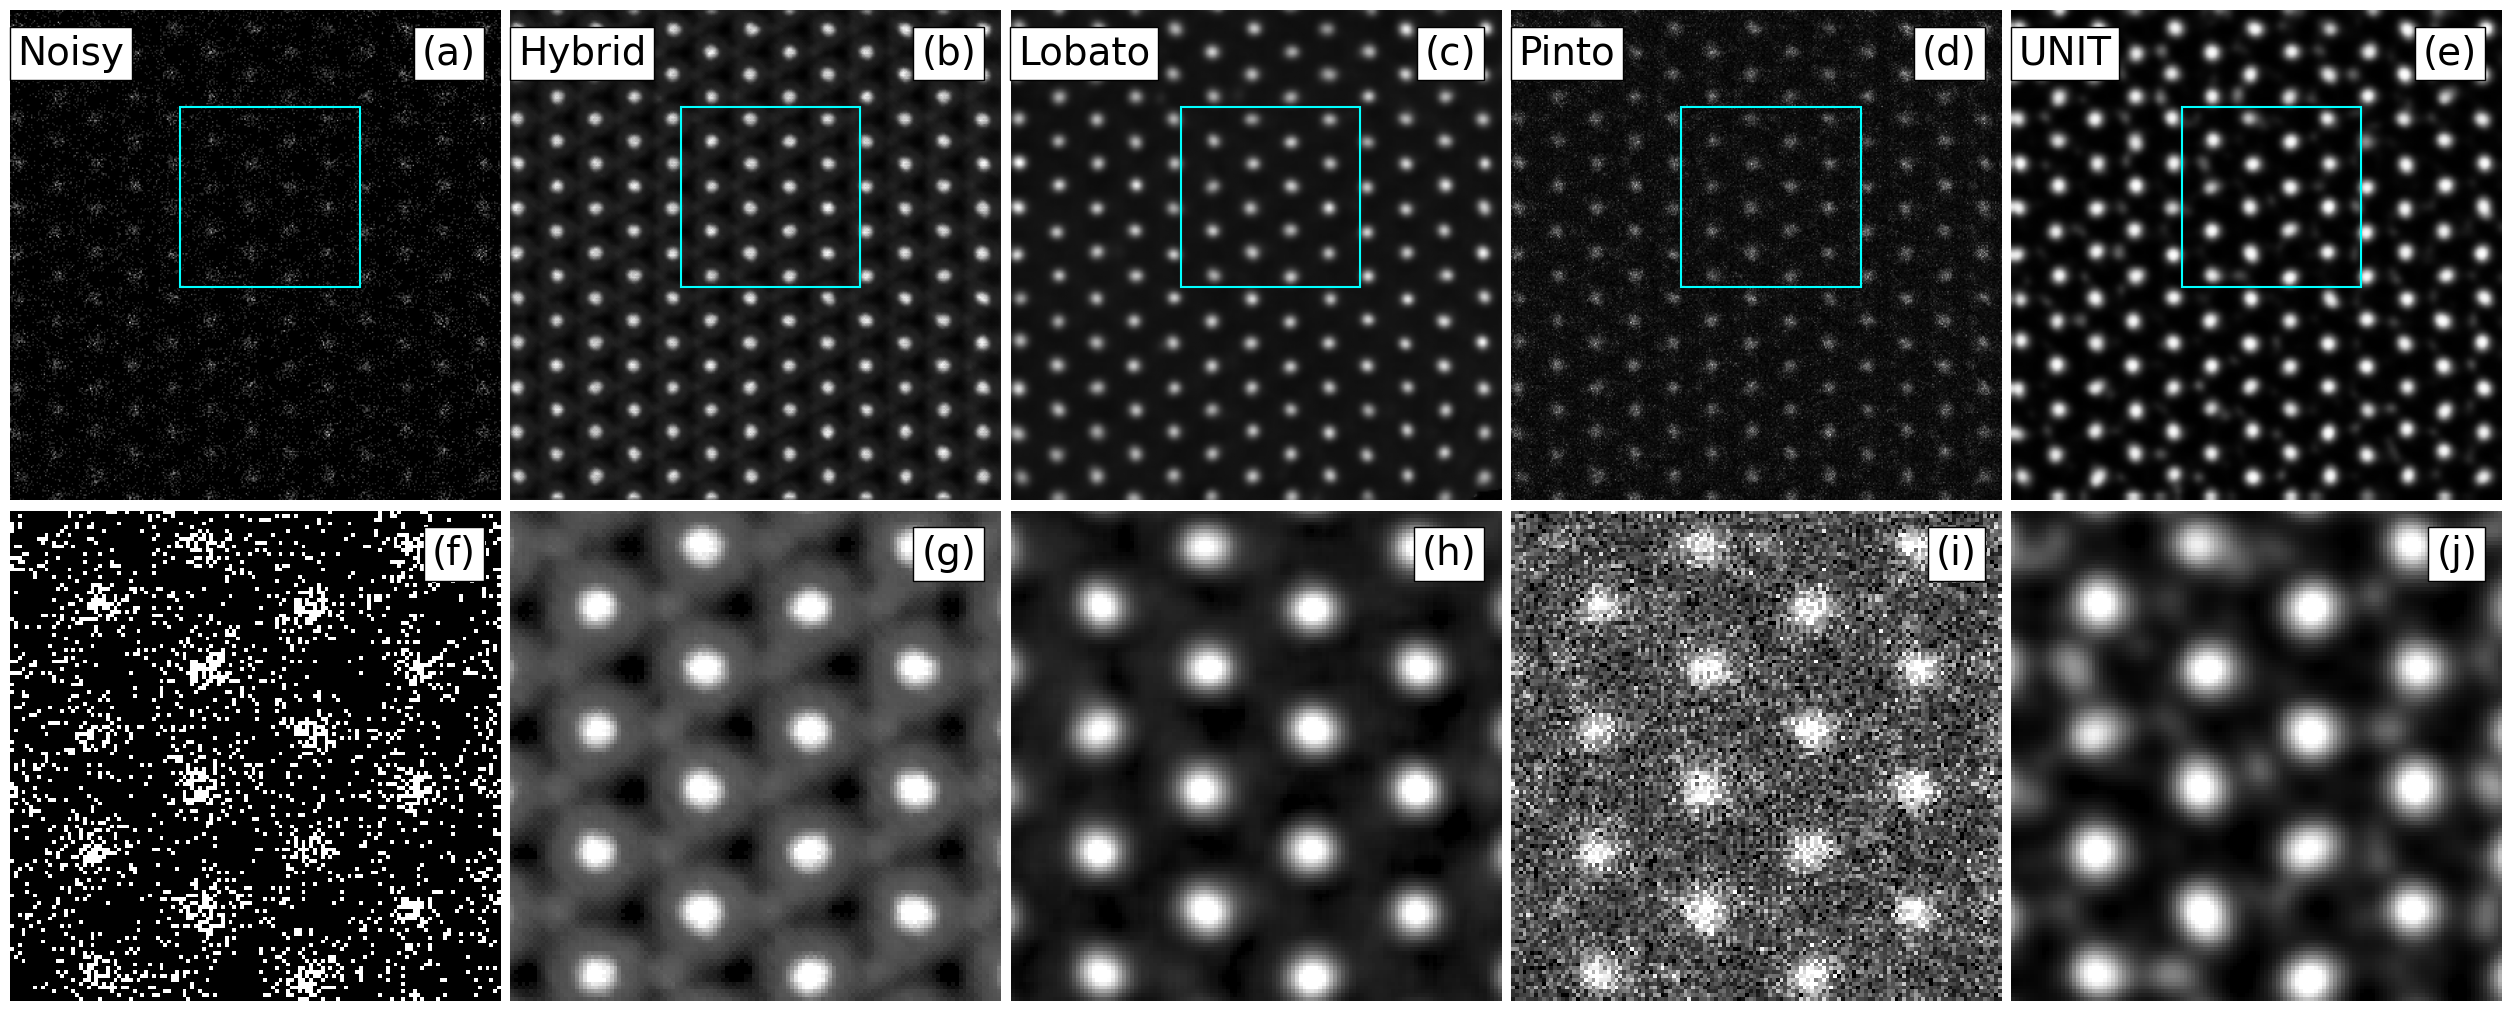

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure, exposure
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
images = images_2
models = ["Noisy", "Hybrid", "Lobato", "Pinto", "UNIT"]
letters_img = ["(a)", "(b)", "(c)", "(d)", "(e)"]
letters_patch = ["(f)", "(g)", "(h)", "(i)", "(j)"]
point1 = (14, 116)
point2 = (253, 254)

patch_size = 128  # pixels

n = len(images)
sub = 2

fig = plt.figure(
    figsize=(5*n, 5*sub),
    constrained_layout=True
)

gs = fig.add_gridspec(sub, n )

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 22
})
for idx, image in enumerate(images):
    # ---------- PATCH center (midpoint of line) ----------
    cy = int(0.5 * (point1[0] + point2[0]))
    cx = int(0.5 * (point1[1] + point2[1]))
    r = patch_size // 2

    y0 = max(cy - r, 0)
    x0 = max(cx - r, 0)
    y1 = min(cy + r, image.shape[0])
    x1 = min(cx + r, image.shape[1])

    patch = image[y0:y1, x0:x1]

    # Histogram normalization (robust)
    p2, p98 = np.percentile(patch, (2, 98))
    patch_norm = exposure.rescale_intensity(
        patch, in_range=(p2, p98), out_range=(0, 1)
    )
    # Brightness boost (gamma correction)
    gamma = 0.6
    patch_bright = exposure.adjust_gamma(patch_norm, gamma)
    # ---------- TOP: full image ----------
    ax_img = fig.add_subplot(gs[0, idx])

    ax_img.imshow(image, cmap='gray')




    # Patch rectangle
    rect = Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        linewidth=1.5,
        edgecolor='cyan',
        facecolor='none'
    )
    ax_img.add_patch(rect)

    ax_img.axis('off')

    # ---------- BOTTOM: enlarged patch ----------
    ax_patch = fig.add_subplot(gs[1, idx])
    ax_patch.imshow(patch_bright, cmap='gray')
    ax_patch.axis('off')

    ax_img.text(0.015, 0.95, models[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='left',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

    ax_img.text(0.95, 0.95, letters_img[idx],
            transform=ax_img.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))

    ax_patch.text(0.95, 0.95, letters_patch[idx],
            transform=ax_patch.transAxes,
            fontsize=28,
            va='top',
            ha='right',
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='square,pad=0.2'))





#plt.tight_layout()
plt.show()
